# Task 3: Car Price Prediction with Machine Learning

## 1. Introduction

### 1.1 Project Overview

The price of a used car depends on several factors, including its brand, age, mileage, fuel type, and transmission.

In this project, we will use Machine Learning to build a model that predicts the selling price of a used car based on information about the vehicle.

We will use the Vehicle Dataset from CarDekho to explore the data, identify patterns, prepare the information, train regression models, and evaluate their performance.

### 1.2 Project Objective

The main objective is to develop a Machine Learning regression model that can predict the selling price of a used car using its features.

We will compare at least two regression models and evaluate their performance using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R²).

### 1.3 Technologies Used

- Python – Programming language used for data analysis and model development.
- Pandas – Used to load, clean, and manipulate datasets.
- NumPy – Used for numerical operations.
- Matplotlib – Used to create data visualisations.
- Seaborn – Used to create statistical charts and graphs.
- Scikit-learn – Used to prepare data, train Machine Learning models, and evaluate their performance.
- Jupyter Notebook – Used to organise and document the project.


## 2. Importing Libraries

### Library Overview

Before analysing the dataset, we need to import the Python libraries required for data manipulation, visualisation, numerical operations, and Machine Learning.

Each library provides specific tools that will help us throughout the project.


In [1]:
#Import pandas for loading and manipulating datasets
import pandas as pd

#Import NumPy for numerical operations
import numpy as np

#Import Matplotlib for creating graphs and visualisations
import matplotlib.pyplot as plt

#Import Seaborn for statistical data visualisations
import seaborn as sns

#Import tools for splitting data into training and testing sets
from sklearn.model_selection import train_test_split

#Import Linear Regression model
from sklearn.linear_model import LinearRegression

# Import Random Forest Regression model
from sklearn.ensemble import RandomForestRegressor

#Import evaluation metrics for measuring model performance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#Import One-Hot Encoding tool for converting categorical data
from sklearn.preprocessing import OneHotEncoder

#Import a tool for combining preprocessing steps and models
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

## 3. Loading and Inspecting the Dataset

### 3.1 Loading the Dataset

The first step in data analysis is loading the dataset into Python.

We will use the Pandas library to read the CarDekho CSV file and store its contents in a DataFrame.

A DataFrame is a two-dimensional data structure that organises information into rows and columns, making it easier to inspect, clean, and analyse data.


In [2]:
#Load the CarDekho dataset from the raw data folder
df = pd.read_csv("data/raw/car data.csv")

#Display the first five rows of the dataset
df.head()


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


### 3.2 Understanding the Dataset Structure

After loading the dataset, we need to inspect its dimensions and structure.

This helps us understand how many car records and features are available. We will also examine the column data types and identify any missing values before beginning the cleaning process.


In [3]:
#Display the number of rows and columns in the dataset
print("Dataset dimensions:", df.shape)

#Display detailed information about the dataset
df.info()


Dataset dimensions: (301, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


### 3.3 Checking for Missing Values and Duplicate Records

Data cleaning is an important part of Machine Learning because poor-quality data can affect the accuracy of a model.

In this step, we will:

- Check each column for missing values.
- Identify duplicate records.
- Determine whether any records need to be removed.

Missing values are empty or unavailable entries, while duplicate records are rows containing repeated information.


In [4]:
#Count the missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

#Count the total number of duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())


Missing values per column:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

Number of duplicate rows:
2


### 3.4 Removing Duplicate Records

The duplicate check identified two repeated rows in the dataset.

To avoid giving repeated records unnecessary influence during analysis and model training, we will remove the duplicates.

After removing them, we will check the dataset dimensions again to confirm that the cleaning operation was successful.


In [5]:
#Remove duplicate rows from the dataset
df = df.drop_duplicates()

#Display the updated dataset dimensions
print("Dataset dimensions after removing duplicates:", df.shape)

#Check the number of remaining duplicate rows
print("Remaining duplicate rows:", df.duplicated().sum())


Dataset dimensions after removing duplicates: (299, 9)
Remaining duplicate rows: 0


### Data Cleaning Observations

The initial dataset contained 301 records and nine columns.

The missing-value check showed that all columns had zero missing values. However, the duplicate check identified two repeated records.

After removing the duplicate rows, the dataset contained 299 records and nine columns, with no remaining duplicates.

The dataset is now free of missing values and exact duplicate records. We can continue checking the consistency of the categorical data.


### 3.5 Checking Inconsistent Categorical Values

Categorical columns contain descriptive information rather than numerical measurements.

Inconsistent spelling, capitalisation, or unnecessary spaces can cause the same category to be interpreted as multiple different values.

We will inspect the unique values in the categorical columns to identify any inconsistencies before applying the necessary cleaning steps.


In [6]:
#Display the unique values in each categorical column
print("Unique car names:", df["Car_Name"].unique())

print("\nUnique fuel types:", df["Fuel_Type"].unique())

print("\nUnique seller types:", df["Seller_Type"].unique())

print("\nUnique transmission types:", df["Transmission"].unique())


Unique car names: ['ritz' 'sx4' 'ciaz' 'wagon r' 'swift' 'vitara brezza' 's cross'
 'alto 800' 'ertiga' 'dzire' 'alto k10' 'ignis' '800' 'baleno' 'omni'
 'fortuner' 'innova' 'corolla altis' 'etios cross' 'etios g' 'etios liva'
 'corolla' 'etios gd' 'camry' 'land cruiser' 'Royal Enfield Thunder 500'
 'UM Renegade Mojave' 'KTM RC200' 'Bajaj Dominar 400'
 'Royal Enfield Classic 350' 'KTM RC390' 'Hyosung GT250R'
 'Royal Enfield Thunder 350' 'KTM 390 Duke ' 'Mahindra Mojo XT300'
 'Bajaj Pulsar RS200' 'Royal Enfield Bullet 350'
 'Royal Enfield Classic 500' 'Bajaj Avenger 220' 'Bajaj Avenger 150'
 'Honda CB Hornet 160R' 'Yamaha FZ S V 2.0' 'Yamaha FZ 16'
 'TVS Apache RTR 160' 'Bajaj Pulsar 150' 'Honda CBR 150' 'Hero Extreme'
 'Bajaj Avenger 220 dtsi' 'Bajaj Avenger 150 street' 'Yamaha FZ  v 2.0'
 'Bajaj Pulsar  NS 200' 'Bajaj Pulsar 220 F' 'TVS Apache RTR 180'
 'Hero Passion X pro' 'Bajaj Pulsar NS 200' 'Yamaha Fazer '
 'Honda Activa 4G' 'TVS Sport ' 'Honda Dream Yuga '
 'Bajaj Avenger Street

### 3.6 Standardising Categorical Values

The categorical inspection showed that the fuel type, seller type, and transmission values have consistent capitalisation.

However, some car names contain unnecessary spaces at the beginning or end of their text.

We will use the Pandas string `strip()` method to remove these spaces from all categorical columns. This will improve consistency without changing the actual names or categories.


In [7]:
#Select all categorical columns
categorical_columns = ["Car_Name", "Fuel_Type", "Seller_Type", "Transmission"]

#Remove unnecessary spaces from categorical values
for column in categorical_columns:
    df[column] = df[column].str.strip()

#Display the unique fuel types after cleaning
print("Fuel types after cleaning:", df["Fuel_Type"].unique())

#Display the unique transmission types after cleaning
print("Transmission types after cleaning:", df["Transmission"].unique())


Fuel types after cleaning: ['Petrol' 'Diesel' 'CNG']
Transmission types after cleaning: ['Manual' 'Automatic']


### 3.7 Standardising Spaces in Car Names

Some car names contain multiple spaces between words. These unnecessary spaces can make similar names appear different.

We will use Pandas string operations to split each car name into individual words and join the words again using a single space.

This helps maintain consistent car names without changing the actual names.

In [8]:
#Replace multiple spaces between words with a single space
df["Car_Name"] = df["Car_Name"].str.split().str.join(" ")

#Display some car names after cleaning
print("Car names after cleaning:")
print(df["Car_Name"].unique())

Car names after cleaning:
['ritz' 'sx4' 'ciaz' 'wagon r' 'swift' 'vitara brezza' 's cross'
 'alto 800' 'ertiga' 'dzire' 'alto k10' 'ignis' '800' 'baleno' 'omni'
 'fortuner' 'innova' 'corolla altis' 'etios cross' 'etios g' 'etios liva'
 'corolla' 'etios gd' 'camry' 'land cruiser' 'Royal Enfield Thunder 500'
 'UM Renegade Mojave' 'KTM RC200' 'Bajaj Dominar 400'
 'Royal Enfield Classic 350' 'KTM RC390' 'Hyosung GT250R'
 'Royal Enfield Thunder 350' 'KTM 390 Duke' 'Mahindra Mojo XT300'
 'Bajaj Pulsar RS200' 'Royal Enfield Bullet 350'
 'Royal Enfield Classic 500' 'Bajaj Avenger 220' 'Bajaj Avenger 150'
 'Honda CB Hornet 160R' 'Yamaha FZ S V 2.0' 'Yamaha FZ 16'
 'TVS Apache RTR 160' 'Bajaj Pulsar 150' 'Honda CBR 150' 'Hero Extreme'
 'Bajaj Avenger 220 dtsi' 'Bajaj Avenger 150 street' 'Yamaha FZ v 2.0'
 'Bajaj Pulsar NS 200' 'Bajaj Pulsar 220 F' 'TVS Apache RTR 180'
 'Hero Passion X pro' 'Yamaha Fazer' 'Honda Activa 4G' 'TVS Sport'
 'Honda Dream Yuga' 'Bajaj Avenger Street 220' 'Hero Splender 

### 3.8 Extracting the Brand from the Car Name

The original dataset contains a `Car_Name` column, but it does not have a separate column identifying the manufacturer.

We will create a new column called `Brand`.

Some records contain only the vehicle model name, while others include the manufacturer's name. To handle this, we will use a dictionary to map model-only names to their correct brands and extract the brand from names that already include it.

This feature will help us examine how vehicle brands relate to selling prices.

In [9]:
#Create a dictionary for vehicle models that do not include their brand
model_to_brand = {
    "ritz": "Maruti Suzuki",
    "sx4": "Maruti Suzuki",
    "ciaz": "Maruti Suzuki",
    "wagon r": "Maruti Suzuki",
    "swift": "Maruti Suzuki",
    "vitara brezza": "Maruti Suzuki",
    "s cross": "Maruti Suzuki",
    "alto 800": "Maruti Suzuki",
    "ertiga": "Maruti Suzuki",
    "dzire": "Maruti Suzuki",
    "alto k10": "Maruti Suzuki",
    "ignis": "Maruti Suzuki",
    "800": "Maruti Suzuki",
    "baleno": "Maruti Suzuki",
    "omni": "Maruti Suzuki",
    "fortuner": "Toyota",
    "innova": "Toyota",
    "corolla altis": "Toyota",
    "etios cross": "Toyota",
    "etios g": "Toyota",
    "etios liva": "Toyota",
    "corolla": "Toyota",
    "camry": "Toyota",
    "land cruiser": "Toyota",
    "i20": "Hyundai",
    "grand i10": "Hyundai",
    "i10": "Hyundai",
    "eon": "Hyundai",
    "xcent": "Hyundai",
    "elantra": "Hyundai",
    "creta": "Hyundai",
    "verna": "Hyundai",
    "city": "Honda",
    "brio": "Honda",
    "amaze": "Honda",
    "jazz": "Honda",
    "activa 3g": "Honda",
    "activa 4g": "Honda"
}

#Create a function to identify the brand
def extract_brand(car_name):

    #Check whether the model name exists in our dictionary
    if car_name.lower() in model_to_brand:
        return model_to_brand[car_name.lower()]

    #Separate the remaining car names into individual words
    words = car_name.split()

    #Handle manufacturer names that contain two words
    if len(words) > 1 and words[0] == "Royal" and words[1] == "Enfield":
        return "Royal Enfield"

    if len(words) > 1 and words[0] == "Hero" and words[1] == "Honda":
        return "Hero Honda"

    #Use the first word as the brand for the remaining names
    return words[0]

#Apply the function to create the Brand column
df["Brand"] = df["Car_Name"].apply(extract_brand)

#Display the first five car names and their extracted brands
print(df[["Car_Name", "Brand"]].head())

#Display all unique brands
print("\nUnique brands:")
print(sorted(df["Brand"].unique()))

  Car_Name          Brand
0     ritz  Maruti Suzuki
1      sx4  Maruti Suzuki
2     ciaz  Maruti Suzuki
3  wagon r  Maruti Suzuki
4    swift  Maruti Suzuki

Unique brands:
['Bajaj', 'Hero', 'Hero Honda', 'Honda', 'Hyosung', 'Hyundai', 'KTM', 'Mahindra', 'Maruti Suzuki', 'Royal Enfield', 'Suzuki', 'TVS', 'Toyota', 'UM', 'Yamaha', 'etios']


### 3.9 Correcting Brand Mapping

After extracting the brands, we noticed that some Toyota Etios models were incorrectly identified as a separate brand.

Etios is a Toyota model. We will update the brand dictionary to include the missing model names and then regenerate the `Brand` column.

This helps improve the accuracy of our newly created feature.

In [10]:
#Add the missing Toyota model to the brand dictionary
model_to_brand["etios gd"] = "Toyota"

#Recreate the Brand column using the updated dictionary
df["Brand"] = df["Car_Name"].apply(extract_brand)

#Display the updated list of unique brands
print("Unique brands after correction:")
print(sorted(df["Brand"].unique()))

Unique brands after correction:
['Bajaj', 'Hero', 'Hero Honda', 'Honda', 'Hyosung', 'Hyundai', 'KTM', 'Mahindra', 'Maruti Suzuki', 'Royal Enfield', 'Suzuki', 'TVS', 'Toyota', 'UM', 'Yamaha']


### 3.10 Creating the Vehicle Age Feature

Feature engineering involves creating new features from existing dataset columns to provide useful information to a Machine Learning model.

The dataset contains a `Year` column representing the vehicle's manufacturing year.

We will create a new feature called `Car_Age` by subtracting the manufacturing year from 2026, the current year.

This allows the model to learn how vehicle age relates to selling price.

In [11]:
#Set the current year
current_year = 2026

#Calculate the age of each vehicle
df["Car_Age"] = current_year - df["Year"]

#Display the manufacturing year and calculated vehicle age
print(df[["Year", "Car_Age"]].head())

   Year  Car_Age
0  2014       12
1  2013       13
2  2017        9
3  2011       15
4  2014       12


### 3.11 Reviewing the Cleaned Dataset

After cleaning the dataset and creating new features, we need to review the updated data.

We will check:

- The updated number of rows and columns.
- The first five records.
- The data types of each column.
- Whether any missing values or duplicate records remain.

This final check helps us confirm that the dataset is ready for Exploratory Data Analysis.

In [12]:
#Display the updated dataset dimensions
print("Updated dataset dimensions:", df.shape)

#Display the first five records
display(df.head())

#Display information about the columns and data types
df.info()

#Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

#Check for duplicate records
print("\nDuplicate records:", df.duplicated().sum())

Updated dataset dimensions: (299, 11)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Brand,Car_Age
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0,Maruti Suzuki,12
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0,Maruti Suzuki,13
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0,Maruti Suzuki,9
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0,Maruti Suzuki,15
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0,Maruti Suzuki,12


<class 'pandas.core.frame.DataFrame'>
Index: 299 entries, 0 to 300
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       299 non-null    object 
 1   Year           299 non-null    int64  
 2   Selling_Price  299 non-null    float64
 3   Present_Price  299 non-null    float64
 4   Kms_Driven     299 non-null    int64  
 5   Fuel_Type      299 non-null    object 
 6   Seller_Type    299 non-null    object 
 7   Transmission   299 non-null    object 
 8   Owner          299 non-null    int64  
 9   Brand          299 non-null    object 
 10  Car_Age        299 non-null    int64  
dtypes: float64(2), int64(4), object(5)
memory usage: 28.0+ KB

Missing values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
Brand            0
Car_Age          0
dtype: int64

Duplicate records: 0


### 4.1 Selling Price Distribution

The selling price is our target variable because it is the value we want the Machine Learning model to predict.

A distribution plot helps us understand:

- The range of vehicle selling prices.
- Whether most vehicles are inexpensive or expensive.
- Whether the dataset contains unusually high selling prices.
- Whether the prices are evenly distributed or concentrated in certain ranges.

We will use a histogram to visualise the distribution of selling prices.

Selling Price Statistics:
count    299.000000
mean       4.589632
std        4.984240
min        0.100000
25%        0.850000
50%        3.510000
75%        6.000000
max       35.000000
Name: Selling_Price, dtype: float64


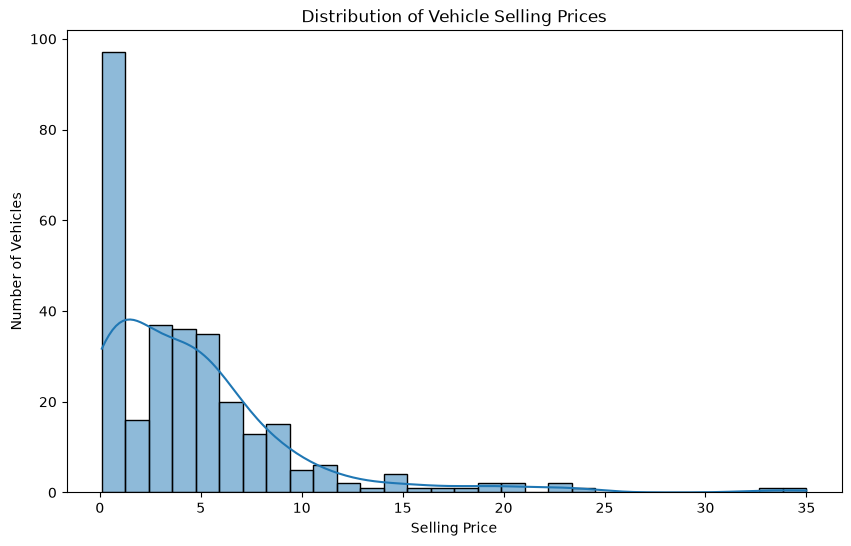

In [13]:
#Display descriptive statistics for selling prices
print("Selling Price Statistics:")
print(df["Selling_Price"].describe())

#Create a histogram of selling prices
plt.figure(figsize=(10, 6))

sns.histplot(data=df, x="Selling_Price", bins=30, kde=True)

#Add a title and axis labels
plt.title("Distribution of Vehicle Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Vehicles")

#Display the graph
plt.show()

#### Observations

The selling price distribution shows that vehicle prices vary considerably.

The dataset contains 299 vehicles, with an average selling price of approximately ₹4.59 lakh and a median selling price of ₹3.51 lakh.

The minimum selling price is ₹0.10 lakh, while the maximum is ₹35 lakh.

The mean is higher than the median, suggesting a right-skewed distribution. This indicates that a smaller number of expensive vehicles may be influencing the average selling price.

Most vehicles appear to be concentrated in the lower selling-price ranges, while fewer vehicles have much higher selling prices.

### 4.2 Selling Price by Fuel Type

Fuel type is a categorical feature that identifies the type of fuel used by a vehicle.

The dataset contains three fuel categories: Petrol, Diesel and CNG.

We will use a box plot to compare selling prices across these categories.

A box plot displays the median, spread and potential outliers in each group. This will help us understand how selling prices vary between fuel types.

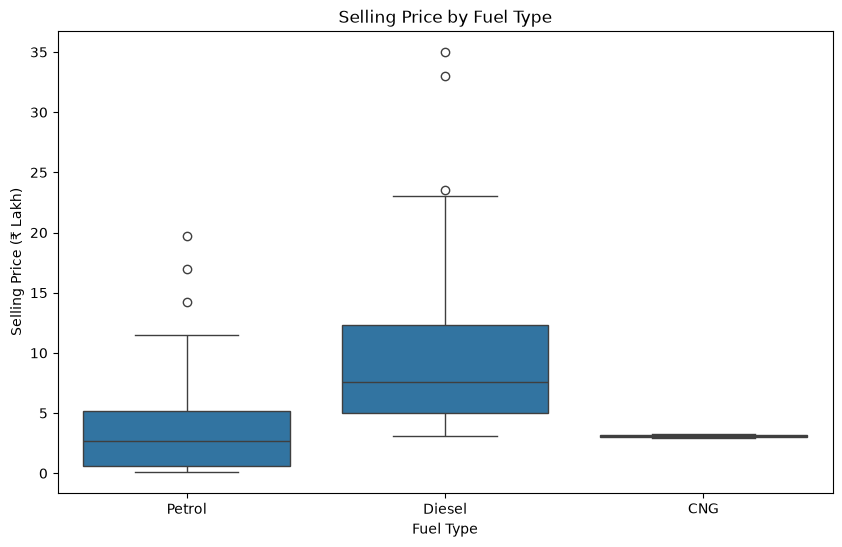

In [14]:
#Create a box plot to compare selling prices by fuel type
plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x="Fuel_Type", y="Selling_Price")

#Add a title and axis labels
plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price (₹ Lakh)")

#Display the graph
plt.show()

#### Observations

The box plot compares vehicle selling prices across Petrol, Diesel and CNG fuel types.

It helps identify differences in median selling prices, price variation and potential outliers among the three fuel categories.

The visualisation allows us to investigate whether fuel type is associated with differences in vehicle selling prices.

### 4.3 Relationship Between Vehicle Age and Selling Price

A vehicle's age can influence its resale value. Older vehicles may have lower selling prices because of depreciation, although other factors can also affect their value.

We will use a scatter plot to investigate the relationship between vehicle age and selling price.

Each point represents one vehicle. This visualisation will help us identify whether selling prices generally decrease as vehicle age increases.

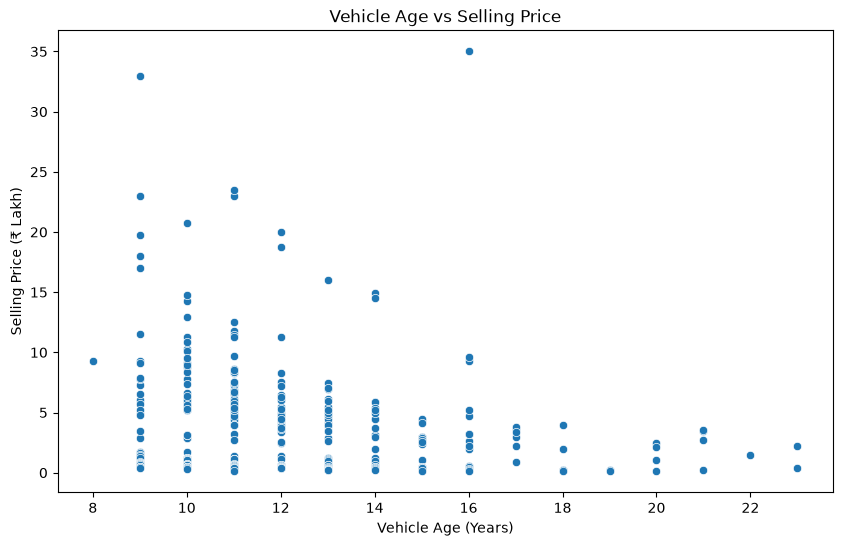

In [15]:
#Create a scatter plot showing vehicle age against selling price
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Car_Age",
    y="Selling_Price"
)

#Add a title and axis labels
plt.title("Vehicle Age vs Selling Price")
plt.xlabel("Vehicle Age (Years)")
plt.ylabel("Selling Price (₹ Lakh)")

#Display the graph
plt.show()

#### Observations

The scatter plot shows the relationship between vehicle age and selling price.

Each point represents an individual vehicle.

The plot helps us examine whether older vehicles generally have lower selling prices than newer vehicles.

Vehicle age appears to be an important feature to investigate when predicting used vehicle prices. However, other factors, such as brand, mileage and present market value, may also influence selling prices.

### 4.4 Feature Correlation Analysis

Correlation measures the strength and direction of a relationship between two numerical variables.

Correlation values range from -1 to +1:

- +1 indicates a perfect positive correlation.
- 0 indicates no linear correlation.
- -1 indicates a perfect negative correlation.

A positive correlation means that two variables tend to increase together.

A negative correlation means that when one variable increases, the other tends to decrease.

We will use a correlation heatmap to examine relationships between numerical features in the dataset.

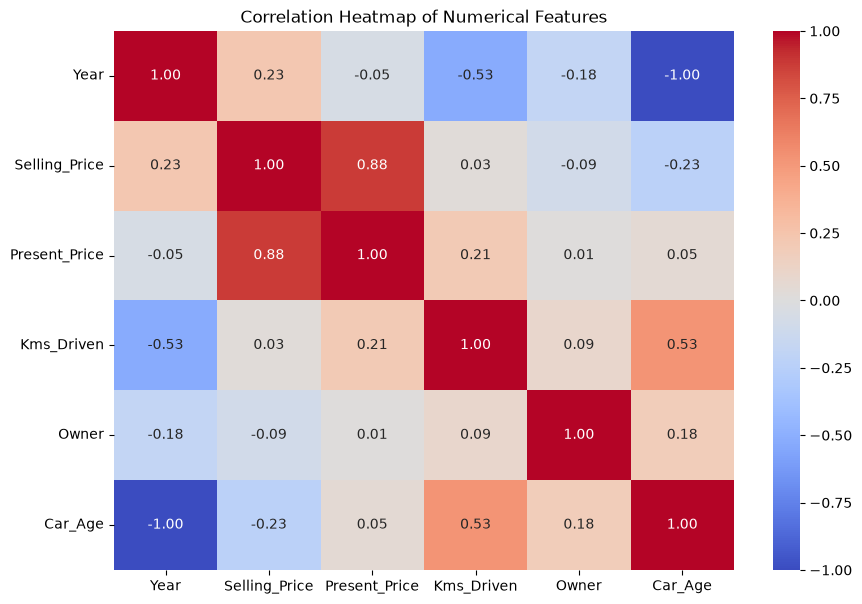

In [16]:
#Select the numerical columns for correlation analysis
numerical_columns = [
    "Year",
    "Selling_Price",
    "Present_Price",
    "Kms_Driven",
    "Owner",
    "Car_Age"
]

#Calculate the correlation matrix
correlation_matrix = df[numerical_columns].corr()

#Create a heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

#Add a title
plt.title("Correlation Heatmap of Numerical Features")

#Display the graph
plt.show()

#### Observations

The correlation heatmap shows several relationships between the numerical features.

Present_Price has a strong positive correlation with Selling_Price, with a correlation value of 0.88. This suggests that vehicles with higher present market prices generally have higher selling prices.

Car_Age has a weak negative correlation with Selling_Price (-0.23), suggesting that older vehicles tend to have slightly lower selling prices.

Kms_Driven (0.03) and Owner (-0.09) show very weak linear relationships with Selling_Price in this dataset.

Year and Car_Age have a perfect negative correlation (-1.00) because Car_Age was calculated directly from Year. These two features contain equivalent information and should not both be included in the final model.

Overall, Present_Price has the strongest linear relationship with Selling_Price among the numerical features. However, correlation does not prove causation.

### 5.1 Selecting Features and Target Variable

Before training a Machine Learning model, we need to separate the input features from the target variable.

Features (X) are the columns used by the model to make predictions.

The target variable (y) is the value that the model needs to predict.

For this project, Selling_Price is our target variable.

We will use Present_Price, Kms_Driven, Fuel_Type, Seller_Type, Transmission, Owner, Brand and Car_Age as our input features.

We will exclude Car_Name because we have already extracted the vehicle brand, and Year because Car_Age contains equivalent information.

In [17]:
#Select the input features for the Machine Learning model
X = df[
    [
        "Present_Price",
        "Kms_Driven",
        "Fuel_Type",
        "Seller_Type",
        "Transmission",
        "Owner",
        "Brand",
        "Car_Age"
    ]
]

#Select the target variable
y = df["Selling_Price"]

#Display the first five input records
print("Input features:")
display(X.head())

#Display the first five target values
print("\nTarget variable:")
print(y.head())

#Display the dimensions of X and y
print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)

Input features:


,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Brand,Car_Age
0,5.59,27000,Petrol,Dealer,Manual,0,Maruti Suzuki,12
1,9.54,43000,Diesel,Dealer,Manual,0,Maruti Suzuki,13
2,9.85,6900,Petrol,Dealer,Manual,0,Maruti Suzuki,9
3,4.15,5200,Petrol,Dealer,Manual,0,Maruti Suzuki,15
4,6.87,42450,Diesel,Dealer,Manual,0,Maruti Suzuki,12



Target variable:
0    3.35
1    4.75
2    7.25
3    2.85
4    4.60
Name: Selling_Price, dtype: float64

Features shape: (299, 8)
Target shape: (299,)


### 5.2 Splitting the Dataset into Training and Testing Sets

A Machine Learning model needs separate training and testing data.

The training dataset is used to teach the model patterns in the input features.

The testing dataset is used to evaluate the model's performance on unseen records.

We will use the train_test_split function from Scikit-learn to divide the dataset.

An 80/20 split will be applied, meaning 80% of the records will be used for training and 20% for testing.

We will also use random_state=42 to make the split reproducible. This means we can obtain the same training and testing records when we run the notebook again.

In [18]:
#Split the features and target into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

#Display the dimensions of each dataset
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (239, 8)
Testing features: (60, 8)
Training target: (239,)
Testing target: (60,)


### 5.3 Encoding Categorical Features

Machine Learning regression models require numerical input values.

However, our dataset contains categorical features such as Fuel_Type, Seller_Type, Transmission and Brand.

We will use One-Hot Encoding to convert these categories into numerical columns.

One-Hot Encoding creates a separate column for each category. A value of 1 indicates that a category is present, while 0 indicates that it is not.

We will use ColumnTransformer to apply encoding only to the categorical columns while keeping the numerical features unchanged.

The encoder will be fitted using the training data only. The same transformation will then be applied to the testing data to prevent information leakage.

In [19]:
#Identify the categorical columns
categorical_columns = [
    "Fuel_Type",
    "Seller_Type",
    "Transmission",
    "Brand"
]

#Identify the numerical columns
numerical_columns = [
    "Present_Price",
    "Kms_Driven",
    "Owner",
    "Car_Age"
]

#Create the One-Hot Encoder
encoder = OneHotEncoder(handle_unknown="ignore")

#Apply encoding to categorical columns
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", encoder, categorical_columns)
    ],
    remainder="passthrough"
)

#Fit the encoder using training data and transform both datasets
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

#Display the shapes after encoding
print("Encoded training features:", X_train_encoded.shape)
print("Encoded testing features:", X_test_encoded.shape)

Encoded training features: (239, 23)
Encoded testing features: (60, 23)


## 6. Training Machine Learning Models

Machine Learning models learn patterns from training data and use those patterns to make predictions on new data.

For this project, we will train and compare two regression models:

1. Linear Regression
2. Random Forest Regression

We will evaluate both models using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and R-squared (R²).

### 6.1 Linear Regression

Linear Regression is a supervised Machine Learning algorithm used to predict numerical values.

It attempts to learn the relationship between input features and a target variable.

In this project, the model will learn how vehicle features such as present price, mileage, fuel type and age relate to selling price.

We will train the model using the encoded training data.

In [20]:
#Create the Linear Regression model
linear_model = LinearRegression()

#Train the model using the training data
linear_model.fit(X_train_encoded, y_train)

#Make predictions using the testing data
linear_predictions = linear_model.predict(X_test_encoded)

#Display the first five predicted selling prices
print("First five Linear Regression predictions:")
print(linear_predictions[:5])

First five Linear Regression predictions:
[ 7.47420821  7.77388308  1.76008736  6.79703028 11.37792016]


#### Linear Regression Predictions

The Linear Regression model was successfully trained using the encoded training dataset.

The trained model was then used to predict selling prices for the testing dataset.

The first five predicted selling prices were approximately ₹7.47 lakh, ₹7.77 lakh, ₹1.76 lakh, ₹6.80 lakh and ₹11.38 lakh.

These predictions will be compared with the actual selling prices using regression evaluation metrics.

### 6.1.2 Evaluating Linear Regression

After training the Linear Regression model, we need to measure its performance.

We will use three regression evaluation metrics:

1. Mean Absolute Error (MAE): Measures the average absolute difference between actual and predicted values.
2. Root Mean Squared Error (RMSE): Measures prediction errors while giving greater weight to larger errors.
3. R-squared (R²): Measures how well the model explains variation in the target variable.

MAE and RMSE are measured in the same units as the selling price. Lower values indicate smaller prediction errors.

An R² value closer to 1 indicates that the model explains more of the variation in selling prices.

In [21]:
#Calculate Mean Absolute Error
linear_mae = mean_absolute_error(y_test, linear_predictions)

#Calculate Root Mean Squared Error
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))

#Calculate R-squared
linear_r2 = r2_score(y_test, linear_predictions)

#Display the evaluation results
print("Linear Regression Performance")
print("MAE:", round(linear_mae, 2))
print("RMSE:", round(linear_rmse, 2))
print("R-squared:", round(linear_r2, 2))

Linear Regression Performance
MAE: 1.52
RMSE: 2.54
R-squared: 0.75


### Linear Regression Evaluation – Observations

The Linear Regression model achieved an MAE of 1.52, an RMSE of 2.54 and an R-squared score of 0.75.

This means that the model's predictions differ from the actual selling prices by approximately ₹1.52 lakh on average. The R-squared score indicates that the model explains about 75% of the variation in vehicle selling prices.

Linear Regression provides a useful baseline for this prediction task. A second regression model will be trained to determine whether prediction performance can be improved.

### 6.2 Random Forest Regression

Random Forest Regression is an ensemble machine learning algorithm that combines predictions from multiple decision trees.

Each decision tree makes its own prediction, and the Random Forest combines these predictions to produce a final result.

This model is useful because it can learn complex relationships between features such as vehicle age, present price, mileage and selling price.

In [22]:
#Create the Random Forest model
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

#Train the model using the encoded training data
random_forest_model.fit(X_train_encoded, y_train)

#Predict selling prices using the test data
rf_predictions = random_forest_model.predict(X_test_encoded)

#Display the first five predictions
print("First five Random Forest predictions:")
print(rf_predictions[:5])

First five Random Forest predictions:
[ 9.4753  7.736   0.4394  7.216  17.4375]


In [23]:
#Calculate Mean Absolute Error
rf_mae = mean_absolute_error(y_test, rf_predictions)

#Calculate Root Mean Squared Error
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))

#Calculate R-squared
rf_r2 = r2_score(y_test, rf_predictions)

#Display the evaluation results
print("Random Forest Performance")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R-squared:", round(rf_r2, 2))

Random Forest Performance
MAE: 1.42
RMSE: 3.49
R-squared: 0.53


### Model Comparison and Observations

Two regression models were trained and evaluated: Linear Regression and Random Forest Regression.

The results showed that:

- Linear Regression achieved an MAE of 1.52, an RMSE of 2.54 and an R-squared score of 0.75.
- Random Forest achieved an MAE of 1.42, an RMSE of 3.49 and an R-squared score of 0.53.

Random Forest had a slightly lower Mean Absolute Error, but Linear Regression performed better in terms of RMSE and R-squared.

Based on these results, Linear Regression is the better overall model for this dataset because it explains more variation in vehicle selling prices and has a lower RMSE.

In [24]:
#Create a table containing both models' results
model_results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [linear_mae, rf_mae],
    "RMSE": [linear_rmse, rf_rmse],
    "R-squared": [linear_r2, rf_r2]
})

#Display the comparison table
display(model_results)

,Model,MAE,RMSE,R-squared
0,Linear Regression,1.519590,2.539935,0.749691
1,Random Forest,1.424322,3.488841,0.527727


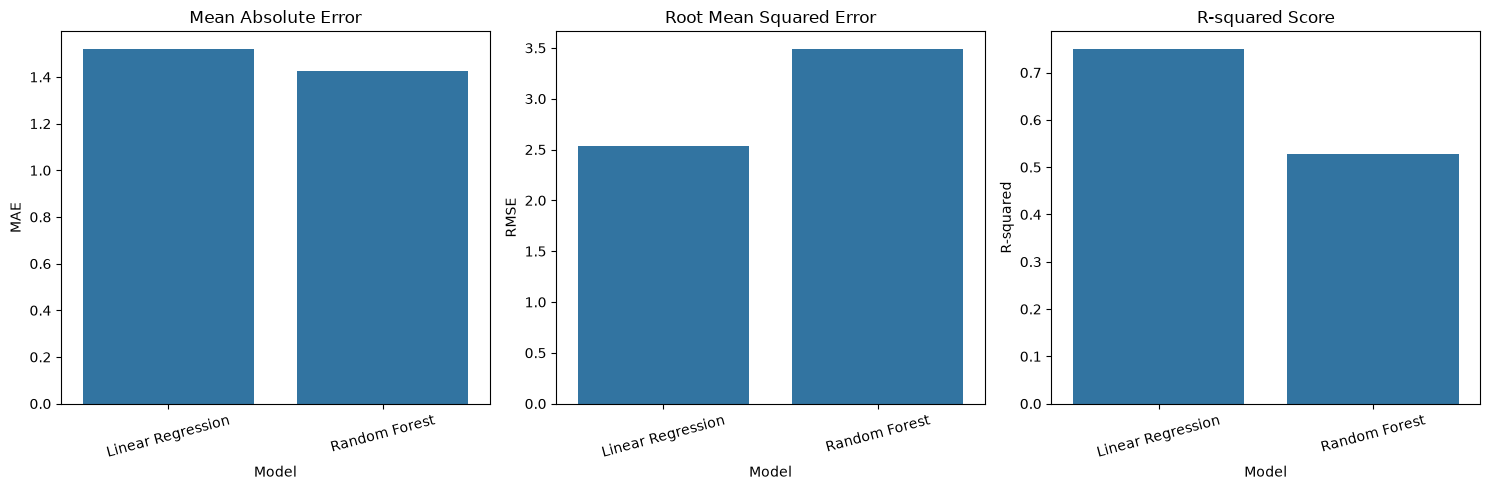

In [25]:
#Create a figure with three side-by-side charts
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

#Compare MAE
sns.barplot(data=model_results, x="Model", y="MAE", ax=axes[0])
axes[0].set_title("Mean Absolute Error")
axes[0].tick_params(axis="x", rotation=15)

#Compare RMSE
sns.barplot(data=model_results, x="Model", y="RMSE", ax=axes[1])
axes[1].set_title("Root Mean Squared Error")
axes[1].tick_params(axis="x", rotation=15)

#Compare R-squared
sns.barplot(data=model_results, x="Model", y="R-squared", ax=axes[2])
axes[2].set_title("R-squared Score")
axes[2].tick_params(axis="x", rotation=15)

#Adjust spacing between charts
plt.tight_layout()

#Display the charts
plt.show()

## 7. Feature Importance

Feature importance helps identify which input features have the greatest influence on the model's predictions.

Since Linear Regression achieved the best overall results, its coefficients will be used to examine the influence of the features.

In [26]:
#Get the names of all encoded features
feature_names = preprocessor.get_feature_names_out()

#Get the coefficients from the Linear Regression model
coefficients = linear_model.coef_

#Create a table containing feature names and coefficients
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

#Calculate the absolute coefficient values
feature_importance["Importance"] = feature_importance["Coefficient"].abs()

#Sort features from most influential to least influential
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

#Display the top 10 features
display(feature_importance.head(10))

,Feature,Coefficient,Importance
1,categorical__Fuel_Type_Diesel,1.110854,1.110854
5,categorical__Transmission_Automatic,0.803595,0.803595
6,categorical__Transmission_Manual,-0.803595,0.803595
4,categorical__Seller_Type_Individual,-0.802549,0.802549
3,categorical__Seller_Type_Dealer,0.802549,0.802549
0,categorical__Fuel_Type_CNG,-0.791329,0.791329
8,categorical__Brand_Hero,0.506154,0.506154
21,remainder__Owner,0.471685,0.471685
17,categorical__Brand_UM,-0.432350,0.432350
19,remainder__Present_Price,0.426553,0.426553


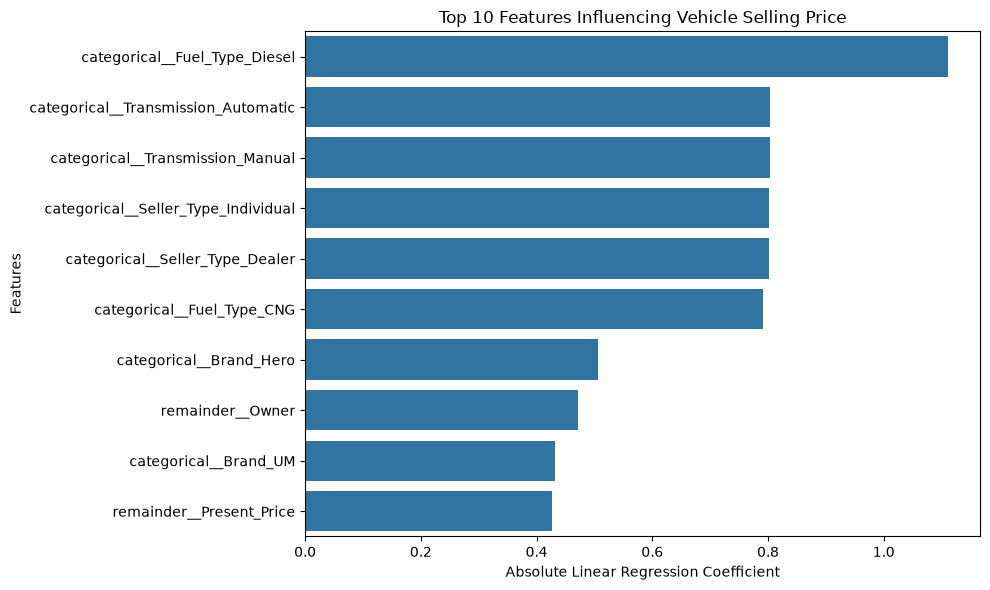

In [27]:
#Select the 10 most important features
top_features = feature_importance.head(10).copy()

#Create a horizontal bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

#Add chart title and labels
plt.title("Top 10 Features Influencing Vehicle Selling Price")
plt.xlabel("Absolute Linear Regression Coefficient")
plt.ylabel("Features")

#Display the chart
plt.tight_layout()
plt.show()

### Feature Importance Observations

The Linear Regression coefficients showed that fuel type, transmission type and seller type had some of the largest absolute coefficients among the encoded features.

Diesel fuel had the largest absolute coefficient in the top 10, followed by transmission and seller type categories.

Present price and vehicle ownership also appeared among the top 10 features.

These results show that vehicle characteristics and market-related factors contribute to the model's selling price predictions. However, coefficient magnitudes should be interpreted carefully because the numerical features have not been scaled.

## 8. Conclusion

This project focused on developing machine learning models to predict used vehicle selling prices using the CarDekho vehicle dataset.

The dataset was cleaned by removing duplicate records and standardising categorical values. Feature engineering was performed by extracting vehicle brands and calculating vehicle age.

Exploratory Data Analysis was used to investigate selling price distributions, fuel types, vehicle age and numerical correlations.

Two regression models were developed and evaluated: Linear Regression and Random Forest Regression.

Linear Regression achieved an MAE of 1.52, RMSE of 2.54 and R-squared score of 0.75. Random Forest achieved an MAE of 1.42, RMSE of 3.49 and R-squared score of 0.53.

Based on the evaluation results, Linear Regression performed better overall, although Random Forest achieved a slightly lower MAE.

The project demonstrated how data cleaning, feature engineering, visualisation and regression algorithms can be used to develop a used vehicle price prediction model.